# 06 - XGBoost
Capped RUL target, shallow trees + subsampling, early stopping on the validation engines.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root (the folder containing utils.py) no matter where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import utils as U

In [2]:
ds = U.load_dataset()               # features, capped targets, engine-wise train/val split, official test targets
tr = ~ds.is_val
print("train rows:", tr.sum(), "| val rows:", ds.is_val.sum(), "| test engines:", len(ds.y_test))

train rows: 16138 | val rows: 4493 | test engines: 100


In [3]:
def report(name, val_pred, test_pred):
    """Validation = all rows of the 20 held-out training engines (capped RUL).
    Test = official protocol: ONE prediction per test engine (last observed cycle) vs RUL_FD001."""
    v = U.score_predictions(ds.y_train[ds.is_val], val_pred)
    t = U.score_predictions(ds.y_test, test_pred)
    print(f"{name}\n  validation  RMSE {v['RMSE']:.2f}  MAE {v['MAE']:.2f}  R2 {v['R2']:.3f}")
    print(f"  test (official)  RMSE {t['RMSE']:.2f}  MAE {t['MAE']:.2f}  R2 {t['R2']:.3f}  NASA score {t['NASA']:.0f}")
    return t

def scatter(test_pred, title):
    plt.figure(figsize=(5, 5))
    plt.scatter(ds.y_test, test_pred, alpha=0.7)
    lim = max(ds.y_test.max(), test_pred.max()) + 5
    plt.plot([0, lim], [0, lim], "r--"); plt.xlabel("True RUL"); plt.ylabel("Predicted RUL")
    plt.title(title); plt.grid(alpha=0.3); plt.show()

base = U.score_predictions(ds.y_test, np.full(len(ds.y_test), ds.train_mean_rul))
print(f"Reference - always predicting the mean training RUL: test RMSE {base['RMSE']:.2f}")

Reference - always predicting the mean training RUL: test RMSE 52.62


best number of trees: 200
XGBoost (train on 80 engines)
  validation  RMSE 18.80  MAE 13.98  R2 0.793
  test (official)  RMSE 18.14  MAE 13.20  R2 0.809  NASA score 931


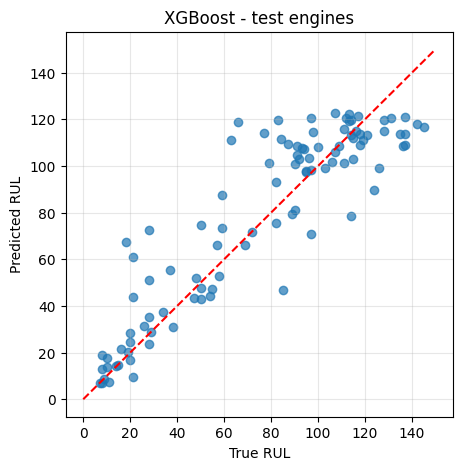

In [4]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=2000, learning_rate=0.03, max_depth=4, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
    early_stopping_rounds=50, eval_metric="rmse", random_state=42, n_jobs=-1,
)
model.fit(ds.X_train.tab[tr], ds.y_train[tr],
          eval_set=[(ds.X_train.tab[ds.is_val], ds.y_train[ds.is_val])], verbose=False)
best_n = model.best_iteration + 1
print("best number of trees:", best_n)

val_pred  = np.clip(model.predict(ds.X_train.tab[ds.is_val]), 0, None)
test_pred = np.clip(model.predict(ds.X_test.tab.iloc[ds.last_idx]), 0, None)
report("XGBoost (train on 80 engines)", val_pred, test_pred)
scatter(test_pred, "XGBoost - test engines")

In [5]:
# Final model: all 100 engines, number of trees fixed from early stopping.
final = XGBRegressor(
    n_estimators=best_n, learning_rate=0.03, max_depth=4, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=42, n_jobs=-1,
).fit(ds.X_train.tab, ds.y_train)
test_pred = np.clip(final.predict(ds.X_test.tab.iloc[ds.last_idx]), 0, None)
t = U.score_predictions(ds.y_test, test_pred)
print("final test RMSE", round(t["RMSE"], 2), "| NASA score", round(t["NASA"]))
joblib.dump(final, U.MODEL_DIR / "xgb_model.pkl")

final test RMSE 17.99 | NASA score 934


['/home/aryan/tt/NASA-C-MAPSS/claud/models/xgb_model.pkl']